# Example 2.1 — Exact structure search (the two enantiomers of crizotinib)

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-opus-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:55:12Z
- **Contents:** 1 exchange · 10 tool calls · 1 figure

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/` and the figures in `figures/`. With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/2.1-exact-structure-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 2.1-exact-structure-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 2.1-exact-structure-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/2.1-exact-structure-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 2.1-exact-structure-notebook-rerun.ipynb 2.1-exact-structure-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

Is (S)-crizotinib in BindingDB as its own compound, separate from crizotinib? Compare the two enantiomers on the targets where both were measured.

In [ ]:
# Call 1 · chemical_name_to_smiles · ran 2026-11-24 04:55:02 UTC
await replay.call(1, 'chemical_name_to_smiles', {'name': 'crizotinib'},
                  sha256='9f9274f934fddc24ad6090fb9128927fd19d6078cafba400349b5da66f13ebfd')

**Call 1** · `chemical_name_to_smiles` · recorded result · sha256 `9f9274f934fd…` · uses PubChem, whose answers can change

| name | smiles |
| --- | --- |
| crizotinib | C\[C@@H\](Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl \|r\| |

```json
{
  "query": "crizotinib",
  "resolved": true,
  "source": "bindingdb",
  "smiles": "C[C@@H](Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl |r|",
  "inchi_key": "KTEIFNKAUNYNJU-GFCCVEGCSA-N",
  "monomerid": 50306682,
  "ambiguous": false
}
```

**candidates**: 1 row

| monomerid | bdbm_id | name | inchi_key | smiles | n_activities |
| --- | --- | --- | --- | --- | --- |
| 50306682 | BDBM50306682 | CRIZOTINIB | KTEIFNKAUNYNJU-GFCCVEGCSA-N | C\[C@@H\](Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl \|r\| | 813 |

**sources_tried**: 1 row

| source | status |
| --- | --- |
| bindingdb | found |


In [ ]:
# Call 2 · chemical_name_to_smiles · ran 2026-11-24 04:55:03 UTC
await replay.call(2, 'chemical_name_to_smiles', {'name': '(S)-crizotinib'},
                  sha256='907664be38be4c1feeb1acb0bfaa2b53d499e5e28ae52a42b5124a505bf12f81')

**Call 2** · `chemical_name_to_smiles` · recorded result · sha256 `907664be38be…` · uses PubChem, whose answers can change

| name | smiles |
| --- | --- |
| (S)-crizotinib | C\[C@H\](Oc1cc(-c2cnn(C3CCNCC3)c2)cnc1N)c1c(Cl)ccc(F)c1Cl |

```json
{
  "query": "(S)-crizotinib",
  "resolved": true,
  "source": "pubchem",
  "smiles": "C[C@H](Oc1cc(-c2cnn(C3CCNCC3)c2)cnc1N)c1c(Cl)ccc(F)c1Cl",
  "inchi_key": "KTEIFNKAUNYNJU-LBPRGKRZSA-N",
  "pubchem_name": "(S)-Crizotinib",
  "pubchem_cid": 56671814
}
```

**bindingdb_matches**: 3 rows

| monomerid | bdbm_id | name | inchi_key | smiles | n_activities | exact_match |
| --- | --- | --- | --- | --- | --- | --- |
| 50352564 | BDBM50352564 | CHEMBL1825141 | KTEIFNKAUNYNJU-LBPRGKRZSA-N | C\[C@H\](Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl \|r\| | 13 | True |
| 50306682 | BDBM50306682 | CRIZOTINIB | KTEIFNKAUNYNJU-GFCCVEGCSA-N | C\[C@@H\](Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl \|r\| | 813 | False |
| 179803 | BDBM179803 | 3-\[1-(2,6-dichloro-3-fluorophenyl)ethoxy\]-5-\[1-(piperidin-4-yl)-1H-pyrazol-4-yl\]pyridin-2-amine (11a) | KTEIFNKAUNYNJU-UHFFFAOYSA-N | CC(Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl | 10 | False |

**sources_tried**: 3 rows

| source | status |
| --- | --- |
| bindingdb | not found |
| opsin | not found |
| pubchem | found |


In [ ]:
# Call 3 · exact_structure_search · ran 2026-11-24 04:55:03 UTC
await replay.call(3, 'exact_structure_search', {'smiles': 'C[C@@H](Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl'},
                  sha256='f7f804f352fc19a20d3d04e8cc515c874263d4f36c7f9962156325ad54f9289f')

**Call 3** · `exact_structure_search` · recorded result · sha256 `f7f804f352fc…`

| name | smiles |
| --- | --- |
| query | C\[C@@H\](Oc1cc(-c2cnn(C3CCNCC3)c2)cnc1N)c1c(Cl)ccc(F)c1Cl |

```json
{
  "query": {
    "input": "C[C@@H](Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl",
    "canonical": "C[C@@H](Oc1cc(-c2cnn(C3CCNCC3)c2)cnc1N)c1c(Cl)ccc(F)c1Cl",
    "inchi_key": "KTEIFNKAUNYNJU-GFCCVEGCSA-N",
    "match": "same canonical isomeric SMILES (salts, stereo, charges and isotopes included)"
  },
  "n_exact_matches": 1
}
```

_1 row_

| monomerid | bdbm_id | name | smiles | mol_weight | n_activities | n_targets |
| --- | --- | --- | --- | --- | --- | --- |
| 50306682 | BDBM50306682 | CRIZOTINIB | C\[C@@H\](Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl \|r\| | 450.337 | 813 | 402 |


In [ ]:
# Call 4 · exact_structure_search · ran 2026-11-24 04:55:04 UTC
await replay.call(4, 'exact_structure_search', {'smiles': 'C[C@H](Oc1cc(-c2cnn(C3CCNCC3)c2)cnc1N)c1c(Cl)ccc(F)c1Cl'},
                  sha256='7d2b93fcb196dd9f707271afbd3a08f3b2aa4f683db177893d04c9b215affa78')

**Call 4** · `exact_structure_search` · recorded result · sha256 `7d2b93fcb196…`

| name | smiles |
| --- | --- |
| query | C\[C@H\](Oc1cc(-c2cnn(C3CCNCC3)c2)cnc1N)c1c(Cl)ccc(F)c1Cl |

```json
{
  "query": {
    "input": "C[C@H](Oc1cc(-c2cnn(C3CCNCC3)c2)cnc1N)c1c(Cl)ccc(F)c1Cl",
    "canonical": "C[C@H](Oc1cc(-c2cnn(C3CCNCC3)c2)cnc1N)c1c(Cl)ccc(F)c1Cl",
    "inchi_key": "KTEIFNKAUNYNJU-LBPRGKRZSA-N",
    "match": "same canonical isomeric SMILES (salts, stereo, charges and isotopes included)"
  },
  "n_exact_matches": 1
}
```

_1 row_

| monomerid | bdbm_id | name | smiles | mol_weight | n_activities | n_targets |
| --- | --- | --- | --- | --- | --- | --- |
| 50352564 | BDBM50352564 | CHEMBL1825141 | C\[C@H\](Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl \|r\| | 449.12 | 13 | 4 |


In [ ]:
# Call 5 · exact_structure_search · ran 2026-11-24 04:55:04 UTC
await replay.call(5, 'exact_structure_search', {'smiles': 'CC(Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl'},
                  sha256='899dc9f666c6d8d6fa3e04b19d88b78140e4732301c8e696f5efd45b6fc21cb8')

**Call 5** · `exact_structure_search` · recorded result · sha256 `899dc9f666c6…`

| name | smiles |
| --- | --- |
| query | CC(Oc1cc(-c2cnn(C3CCNCC3)c2)cnc1N)c1c(Cl)ccc(F)c1Cl |

```json
{
  "query": {
    "input": "CC(Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl",
    "canonical": "CC(Oc1cc(-c2cnn(C3CCNCC3)c2)cnc1N)c1c(Cl)ccc(F)c1Cl",
    "inchi_key": "KTEIFNKAUNYNJU-UHFFFAOYSA-N",
    "match": "same canonical isomeric SMILES (salts, stereo, charges and isotopes included)"
  },
  "n_exact_matches": 1
}
```

_1 row_

| monomerid | bdbm_id | name | smiles | mol_weight | n_activities | n_targets |
| --- | --- | --- | --- | --- | --- | --- |
| 179803 | BDBM179803 | 3-\[1-(2,6-dichloro-3-fluorophenyl)ethoxy\]-5-\[1-(piperidin-4-yl)-1H-pyrazol-4-yl\]pyridin-2-amine (11a) | CC(Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl | 449.12 | 10 | 6 |


In [ ]:
# Call 6 · similarity_search · ran 2026-11-24 04:55:12 UTC
await replay.call(6, 'similarity_search', {'smiles': 'C[C@H](Oc1cc(-c2cnn(C3CCNCC3)c2)cnc1N)c1c(Cl)ccc(F)c1Cl', 'threshold': 1.0},
                  sha256='c79d3090f6674133d9ed0467b8eef798dd208a46b4d5644f6c6b307073f4bb52')

**Call 6** · `similarity_search` · recorded result · sha256 `c79d3090f667…`

| name | smiles |
| --- | --- |
| query | C\[C@H\](Oc1cc(-c2cnn(C3CCNCC3)c2)cnc1N)c1c(Cl)ccc(F)c1Cl |

```json
{
  "query": {
    "input": "C[C@H](Oc1cc(-c2cnn(C3CCNCC3)c2)cnc1N)c1c(Cl)ccc(F)c1Cl",
    "canonical": "C[C@H](Oc1cc(-c2cnn(C3CCNCC3)c2)cnc1N)c1c(Cl)ccc(F)c1Cl",
    "threshold": 1.0,
    "fingerprint": "Morgan radius 2, 2048 bits, largest fragment"
  },
  "n_similar_compounds": 3,
  "compounds_searched": 1466457,
  "search_set_size": 1466457
}
```

_3 rows_

| monomerid | bdbm_id | name | smiles | mol_weight | n_activities | n_targets | similarity |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 50306682 | BDBM50306682 | CRIZOTINIB | C\[C@@H\](Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl \|r\| | 450.337 | 813 | 402 | 1 |
| 50352564 | BDBM50352564 | CHEMBL1825141 | C\[C@H\](Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl \|r\| | 449.12 | 13 | 4 | 1 |
| 179803 | BDBM179803 | 3-\[1-(2,6-dichloro-3-fluorophenyl)ethoxy\]-5-\[1-(piperidin-4-yl)-1H-pyrazol-4-yl\]pyridin-2-amine (11a) | CC(Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl | 449.12 | 10 | 6 | 1 |


In [ ]:
# Call 7 · find_targets_for_compound · ran 2026-11-24 04:55:12 UTC
await replay.call(7, 'find_targets_for_compound', {'monomerid': 50352564, 'best_per_target': False},
                  sha256='c2e06db5c026d5bfa8f485cf3d13d6cb3bf365c72297fde88277f3c743a840f8')

**Call 7** · `find_targets_for_compound` · recorded result · sha256 `c2e06db5c026…`

_13 rows_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50552355 | Kd | = | 38 | nM | 7.42 | 50352564 | CHEMBL1825141 | 4906 |  | Hepatocyte growth factor receptor | P08581 | Homo sapiens |  |  | ChEMBL\_1634387 (CHEMBL3877179) | 28280261 | 10.1038/nrd.2016.266 | 2017 |
| 51354914 | Kd | = | 39 | nM | 7.41 | 50352564 | CHEMBL1825141 | 9756 |  | Oxidized purine nucleoside triphosphate hydrolase | P36639 | Homo sapiens |  |  | ChEMBL\_2020004 (CHEMBL4673817) | 26878898 | 10.1021/acs.jmedchem.5b01760 | 2016 |
| 51354925 | IC50 | = | 138 | nM | 6.86 | 50352564 | CHEMBL1825141 | 9756 |  | Oxidized purine nucleoside triphosphate hydrolase | P36639 | Homo sapiens |  |  | ChEMBL\_2020017 (CHEMBL4673830) | 26878898 | 10.1021/acs.jmedchem.5b01760 | 2016 |
| 50659320 | Ki | = | 161 | nM | 6.79 | 50352564 | CHEMBL1825141 | 4906 |  | Hepatocyte growth factor receptor | P08581 | Homo sapiens |  |  | ChEMBL\_767240 (CHEMBL1825352) | 21812414 | 10.1021/jm2007613 | 2011 |
| 50489901 | IC50 | = | 330 | nM | 6.48 | 50352564 | CHEMBL1825141 | 9756 |  | Oxidized purine nucleoside triphosphate hydrolase | P36639 | Homo sapiens |  |  | ChEMBL\_1572469 (CHEMBL3796329) | 26924380 | 10.1021/acs.jmedchem.6b00283 | 2016 |
| 50552339 | IC50 | = | 330 | nM | 6.48 | 50352564 | CHEMBL1825141 | 9756 |  | Oxidized purine nucleoside triphosphate hydrolase | P36639 | Homo sapiens |  |  | ChEMBL\_1634435 (CHEMBL3877227) | 28280261 | 10.1038/nrd.2016.266 | 2017 |
| 51250504 | IC50 | = | 330 | nM | 6.48 | 50352564 | CHEMBL1825141 | 9756 |  | Oxidized purine nucleoside triphosphate hydrolase | P36639 | Homo sapiens |  |  | ChEMBL\_1844827 (CHEMBL4345254) | 32184970 | 10.1021/acsmedchemlett.9b00420 | 2020 |
| 51250473 | IC50 | = | 366 | nM | 6.44 | 50352564 | CHEMBL1825141 | 9756 |  | Oxidized purine nucleoside triphosphate hydrolase | P36639 | Homo sapiens |  |  | ChEMBL\_1844828 (CHEMBL4345255) | 32184970 | 10.1021/acsmedchemlett.9b00420 | 2020 |
| 50552352 | IC50 | = | 408 | nM | 6.39 | 50352564 | CHEMBL1825141 | 9756 |  | Oxidized purine nucleoside triphosphate hydrolase | P36639 | Homo sapiens |  |  | ChEMBL\_1634436 (CHEMBL3877228) | 28280261 | 10.1038/nrd.2016.266 | 2017 |
| 50552343 | Kd | = | 525 | nM | 6.28 | 50352564 | CHEMBL1825141 | 5809 |  | ALK tyrosine kinase receptor | Q9UM73 | Homo sapiens |  |  | ChEMBL\_1634388 (CHEMBL3877180) | 28280261 | 10.1038/nrd.2016.266 | 2017 |
| 51355142 | IC50 | = | 680 | nM | 6.17 | 50352564 | CHEMBL1825141 | 50003928 |  | Mitogen-activated protein kinase kinase kinase kinase 3 | Q8IVH8 | Homo sapiens |  |  | ChEMBL\_2020700 (CHEMBL4674513) | 29636220 | 10.1016/j.bmcl.2018.03.032 | 2018 |
| 51245733 | IC50 | = | 1800 | nM | 5.74 | 50352564 | CHEMBL1825141 | 9756 |  | Oxidized purine nucleoside triphosphate hydrolase | P36639 | Homo sapiens |  |  | ChEMBL\_1839104 (CHEMBL4339319) | 30771603 | 10.1016/j.ejmech.2019.02.011 | 2019 |
| 51354906 | EC50 | = | 3600 | nM | 5.44 | 50352564 | CHEMBL1825141 | 9756 |  | Oxidized purine nucleoside triphosphate hydrolase | P36639 | Homo sapiens |  |  | ChEMBL\_2020002 (CHEMBL4673815) | 26878898 | 10.1021/acs.jmedchem.5b01760 | 2016 |


In [ ]:
# Call 8 · find_targets_for_compound · ran 2026-11-24 04:55:12 UTC
await replay.call(8, 'find_targets_for_compound', {'monomerid': 179803, 'best_per_target': False},
                  sha256='db84c33069c012aca142d76acc99321377a67ebbb552a5bd3a93471b319cf780')

**Call 8** · `find_targets_for_compound` · recorded result · sha256 `db84c33069c0…`

_10 rows_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 326449 | IC50 | = | 14.6 | nM | 7.84 | 179803 | 3-\[1-(2,6-dichloro-3-fluorophenyl)ethoxy\]-5-\[1-(piperidin-4-yl)-1H-pyrazol-4-yl\]pyridin-2-amine (11a) | 7720 |  | Isoform 2 of Hepatocyte growth factor receptor (2) | P08581-2 | Homo sapiens | 7 | 298.15 | c-Met Z-LYTE Assay | 26950400 | 10.1016/j.bioorg.2016.02.009 | 2016 |
| 326457 | IC50 | = | 17.6 | nM | 7.75 | 179803 | 3-\[1-(2,6-dichloro-3-fluorophenyl)ethoxy\]-5-\[1-(piperidin-4-yl)-1H-pyrazol-4-yl\]pyridin-2-amine (11a) | 5809 |  | ALK tyrosine kinase receptor | Q9UM73 | Homo sapiens | 7.5 | 298.15 | ALK HTRF Assays | 26950400 | 10.1016/j.bioorg.2016.02.009 | 2016 |
| 490354 | IC50 | = | 36 | nM | 7.44 | 179803 | 3-\[1-(2,6-dichloro-3-fluorophenyl)ethoxy\]-5-\[1-(piperidin-4-yl)-1H-pyrazol-4-yl\]pyridin-2-amine (11a) | 5809 |  | ALK tyrosine kinase receptor | Q9UM73 | Homo sapiens |  | 298.15 |  Inhibitory Activity Against Anaplastic Lymphoma Kinase (ALK) | US10053458-B2 |  | 2018 |
| 51247631 | IC50 | = | 92 | nM | 7.04 | 179803 | 3-\[1-(2,6-dichloro-3-fluorophenyl)ethoxy\]-5-\[1-(piperidin-4-yl)-1H-pyrazol-4-yl\]pyridin-2-amine (11a) | 4918 |  | Tyrosine-protein kinase JAK2 | O60674 | Homo sapiens |  |  | ChEMBL\_1841388 (CHEMBL4341687) | 30981578 | 10.1016/j.bmcl.2019.04.011 | 2019 |
| 326465 | IC50 | = | 133 | nM | 6.88 | 179803 | 3-\[1-(2,6-dichloro-3-fluorophenyl)ethoxy\]-5-\[1-(piperidin-4-yl)-1H-pyrazol-4-yl\]pyridin-2-amine (11a) | 115 |  | ALK tyrosine kinase receptor \[C1156Y\] | Q9UM73\[C1156Y\] | Homo sapiens | 7.5 | 298.15 | ALK HTRF Assays | 26950400 | 10.1016/j.bioorg.2016.02.009 | 2016 |
| 50416930 | Ki | = | 200 | nM | 6.7 | 179803 | 3-\[1-(2,6-dichloro-3-fluorophenyl)ethoxy\]-5-\[1-(piperidin-4-yl)-1H-pyrazol-4-yl\]pyridin-2-amine (11a) | 4906 |  | Hepatocyte growth factor receptor | P08581 | Homo sapiens |  |  | ChEMBL\_2600284 | 39128361 | 10.1016/j.bmc.2024.117870 |  |
| 490355 | IC50 | = | 220 | nM | 6.66 | 179803 | 3-\[1-(2,6-dichloro-3-fluorophenyl)ethoxy\]-5-\[1-(piperidin-4-yl)-1H-pyrazol-4-yl\]pyridin-2-amine (11a) | 65 |  | ALK tyrosine kinase receptor \[L1196M\] | Q9UM73\[L1196M\] | Homo sapiens |  |  |  | US10053458-B2 |  | 2018 |
| 326473 | IC50 | = | 337 | nM | 6.47 | 179803 | 3-\[1-(2,6-dichloro-3-fluorophenyl)ethoxy\]-5-\[1-(piperidin-4-yl)-1H-pyrazol-4-yl\]pyridin-2-amine (11a) | 65 |  | ALK tyrosine kinase receptor \[L1196M\] | Q9UM73\[L1196M\] | Homo sapiens | 7.5 | 298.15 | ALK HTRF Assays | 26950400 | 10.1016/j.bioorg.2016.02.009 | 2016 |
| 51484759 | IC50 | = | 800 | nM | 6.1 | 179803 | 3-\[1-(2,6-dichloro-3-fluorophenyl)ethoxy\]-5-\[1-(piperidin-4-yl)-1H-pyrazol-4-yl\]pyridin-2-amine (11a) | 5809 |  | ALK tyrosine kinase receptor | Q9UM73 | Homo sapiens |  |  | ChEMBL\_2226745 (CHEMBL5140258) | 35665691 | 10.1016/j.ejmech.2022.114488 | 2022 |
| 51484687 | IC50 | \> | 10000 | nM | 5 | 179803 | 3-\[1-(2,6-dichloro-3-fluorophenyl)ethoxy\]-5-\[1-(piperidin-4-yl)-1H-pyrazol-4-yl\]pyridin-2-amine (11a) | 5809 |  | ALK tyrosine kinase receptor | Q9UM73 | Homo sapiens |  |  | ChEMBL\_2226744 (CHEMBL5140257) | 35665691 | 10.1016/j.ejmech.2022.114488 | 2022 |


In [ ]:
# Call 9 · run_sql · ran 2026-11-24 04:55:12 UTC
sql = """
    SELECT a.monomerid, a.target_name, a.uniprot_raw, a.source_id, a.affinity_type, a.relation, a.value, a.assay_name, a.ki_result_id FROM activity a WHERE a.monomerid IN (50306682, 50352564) AND a.uniprot IN ('P08581','Q9UM73','Q8IVH8','P36639') AND a.source_id IN (SELECT DISTINCT source_id FROM activity WHERE monomerid = 50352564) ORDER BY a.uniprot_raw, a.source_id, a.affinity_type, a.monomerid, a.value, a.ki_result_id
    
"""
await replay.call(9, 'run_sql', {'sql': sql},
                  sha256='8c2ab67baab1b38876dd0ba66d856a41cf7c50bdbca399a2a8525a87b60c2685')

**Call 9** · `run_sql` · recorded result · sha256 `8c2ab67baab1…`

_25 rows_

| monomerid | target_name | uniprot_raw | source_id | affinity_type | relation | value | assay_name | ki_result_id |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50306682 | Hepatocyte growth factor receptor | P08581 | 21812414 | IC50 | \< | 1 | ChEMBL\_767243 (CHEMBL1825355) | 50176432 |
| 50306682 | Hepatocyte growth factor receptor | P08581 | 21812414 | IC50 | = | 8 | ChEMBL\_767236 (CHEMBL1826482) | 50176442 |
| 50306682 | Hepatocyte growth factor receptor | P08581 | 21812414 | IC50 | = | 18 | ChEMBL\_767236 (CHEMBL1826482) | 50176461 |
| 50306682 | Hepatocyte growth factor receptor | P08581 | 21812414 | Ki | = | 2 | ChEMBL\_767240 (CHEMBL1825352) | 50176446 |
| 50306682 | Hepatocyte growth factor receptor | P08581 | 21812414 | Ki | = | 19 | ChEMBL\_767240 (CHEMBL1825352) | 50659316 |
| 50352564 | Hepatocyte growth factor receptor | P08581 | 21812414 | Ki | = | 161 | ChEMBL\_767240 (CHEMBL1825352) | 50659320 |
| 50306682 | Hepatocyte growth factor receptor | P08581 | 28280261 | Kd | = | 0.2 | ChEMBL\_1634387 (CHEMBL3877179) | 50552356 |
| 50352564 | Hepatocyte growth factor receptor | P08581 | 28280261 | Kd | = | 38 | ChEMBL\_1634387 (CHEMBL3877179) | 50552355 |
| 50352564 | Oxidized purine nucleoside triphosphate hydrolase | P36639 | 26878898 | EC50 | = | 3600 | ChEMBL\_2020002 (CHEMBL4673815) | 51354906 |
| 50352564 | Oxidized purine nucleoside triphosphate hydrolase | P36639 | 26878898 | IC50 | = | 138 | ChEMBL\_2020017 (CHEMBL4673830) | 51354925 |
| 50352564 | Oxidized purine nucleoside triphosphate hydrolase | P36639 | 26878898 | Kd | = | 39 | ChEMBL\_2020004 (CHEMBL4673817) | 51354914 |
| 50352564 | Oxidized purine nucleoside triphosphate hydrolase | P36639 | 26924380 | IC50 | = | 330 | ChEMBL\_1572469 (CHEMBL3796329) | 50489901 |
| 50352564 | Oxidized purine nucleoside triphosphate hydrolase | P36639 | 28280261 | IC50 | = | 330 | ChEMBL\_1634435 (CHEMBL3877227) | 50552339 |
| 50352564 | Oxidized purine nucleoside triphosphate hydrolase | P36639 | 28280261 | IC50 | = | 408 | ChEMBL\_1634436 (CHEMBL3877228) | 50552352 |
| 50352564 | Oxidized purine nucleoside triphosphate hydrolase | P36639 | 30771603 | IC50 | = | 1800 | ChEMBL\_1839104 (CHEMBL4339319) | 51245733 |
| 50352564 | Oxidized purine nucleoside triphosphate hydrolase | P36639 | 32184970 | IC50 | = | 330 | ChEMBL\_1844827 (CHEMBL4345254) | 51250504 |
| 50352564 | Oxidized purine nucleoside triphosphate hydrolase | P36639 | 32184970 | IC50 | = | 366 | ChEMBL\_1844828 (CHEMBL4345255) | 51250473 |
| 50306682 | Mitogen-activated protein kinase kinase kinase kinase 3 | Q8IVH8 | 29636220 | IC50 | = | 49 | ChEMBL\_2020700 (CHEMBL4674513) | 51355147 |
| 50306682 | Mitogen-activated protein kinase kinase kinase kinase 3 | Q8IVH8 | 29636220 | IC50 | = | 1700 | ChEMBL\_2020699 (CHEMBL4674512) | 51355130 |
| 50352564 | Mitogen-activated protein kinase kinase kinase kinase 3 | Q8IVH8 | 29636220 | IC50 | = | 680 | ChEMBL\_2020700 (CHEMBL4674513) | 51355142 |
| 50306682 | Mitogen-activated protein kinase kinase kinase kinase 3 | Q8IVH8 | 29636220 | Kd | = | 75 | ChEMBL\_2020261 (CHEMBL4674074) | 51355126 |
| 50306682 | ALK tyrosine kinase receptor | Q9UM73 | 21812414 | IC50 | \< | 1 | ChEMBL\_767246 (CHEMBL1825358) | 50176462 |
| 50306682 | ALK tyrosine kinase receptor | Q9UM73 | 21812414 | IC50 | = | 20 | ChEMBL\_767244 (CHEMBL1825356) | 50176448 |
| 50306682 | ALK tyrosine kinase receptor | Q9UM73 | 28280261 | Kd | = | 4.4 | ChEMBL\_1634388 (CHEMBL3877180) | 50552357 |
| 50352564 | ALK tyrosine kinase receptor | Q9UM73 | 28280261 | Kd | = | 525 | ChEMBL\_1634388 (CHEMBL3877180) | 50552343 |


In [ ]:
# Call 10 · run_sql · ran 2026-11-24 04:55:12 UTC
sql = """
    SELECT uniprot, affinity_type, count(*) AS n, count(*) FILTER (WHERE relation = '=') AS n_exact, count(DISTINCT source_id) AS n_sources, median(value) FILTER (WHERE relation = '=') AS median_nm FROM activity WHERE monomerid = 50306682 AND uniprot IN ('P08581','P36639') GROUP BY uniprot, affinity_type ORDER BY uniprot, affinity_type
    
"""
await replay.call(10, 'run_sql', {'sql': sql},
                  sha256='e3cebf9cbae3aa85cb0a611bb77ab1afa044cae4dd9a9e16703b3813452a6b48')

**Call 10** · `run_sql` · recorded result · sha256 `e3cebf9cbae3…`

_3 rows_

| uniprot | affinity_type | n | n_exact | n_sources | median_nm |
| --- | --- | --- | --- | --- | --- |
| P08581 | IC50 | 51 | 47 | 39 | 8 |
| P08581 | Kd | 7 | 7 | 4 | 2 |
| P08581 | Ki | 12 | 12 | 4 | 14 |


**Figure 1: Crizotinib's three records in BindingDB.** _(as recorded)_

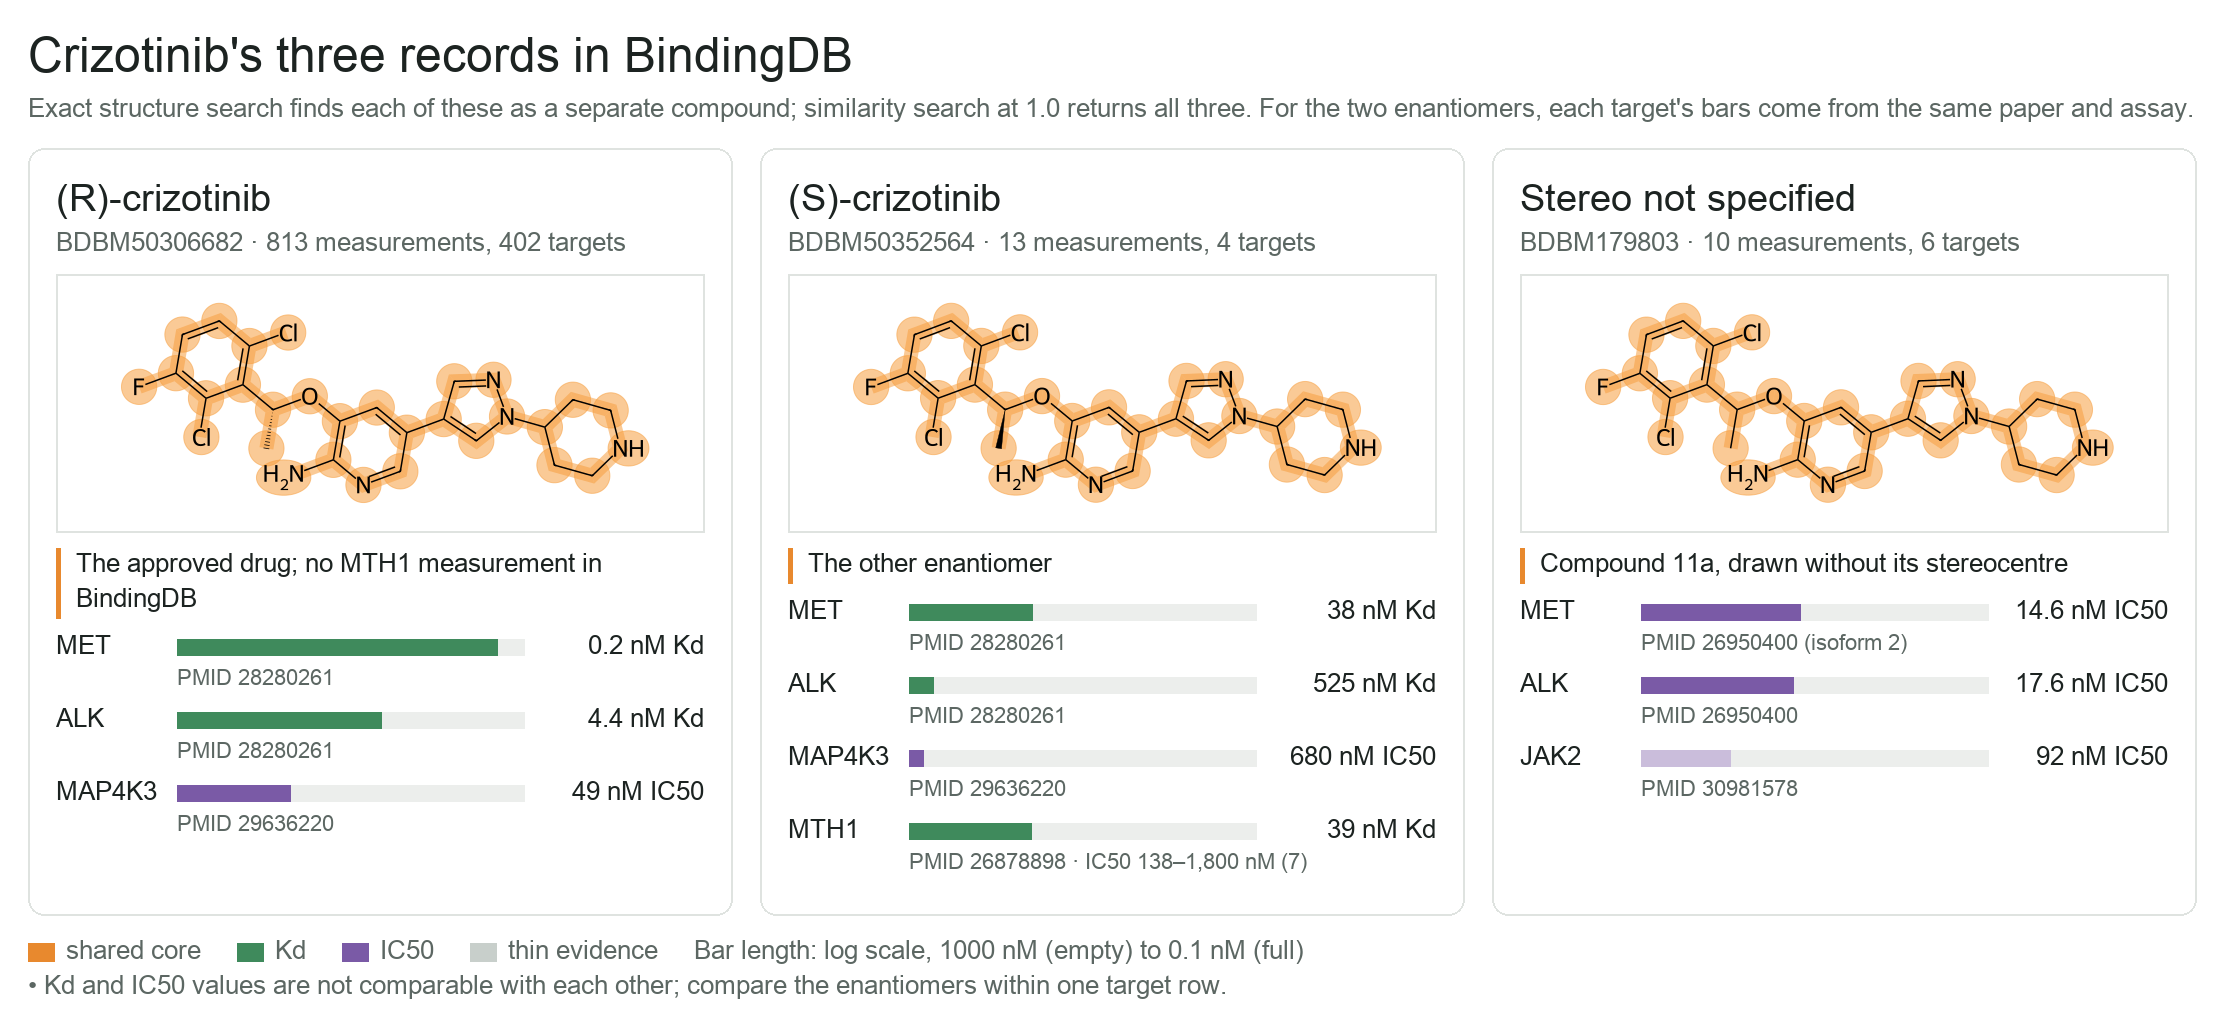

In [ ]:
# Figure 1 · draw_structure_grid draws it again
arguments = {
    'title': "Crizotinib's three records in BindingDB",
    'compounds': [
        {
            'smiles': 'C[C@@H](Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl',
            'title': '(R)-crizotinib',
            'subtitle': 'BDBM50306682 · 813 measurements, 402 targets',
            'caption': 'The approved drug; no MTH1 measurement in BindingDB',
            'bars': [
                {'label': 'MET', 'value_nm': 0.2, 'type': 'Kd', 'note': 'PMID 28280261'},
                {'label': 'ALK', 'value_nm': 4.4, 'type': 'Kd', 'note': 'PMID 28280261'},
                {'label': 'MAP4K3', 'value_nm': 49.0, 'type': 'IC50', 'note': 'PMID 29636220'},
            ],
        },
        {
            'smiles': 'C[C@H](Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl',
            'title': '(S)-crizotinib',
            'subtitle': 'BDBM50352564 · 13 measurements, 4 targets',
            'caption': 'The other enantiomer',
            'bars': [
                {'label': 'MET', 'value_nm': 38.0, 'type': 'Kd', 'note': 'PMID 28280261'},
                {'label': 'ALK', 'value_nm': 525.0, 'type': 'Kd', 'note': 'PMID 28280261'},
                {'label': 'MAP4K3', 'value_nm': 680.0, 'type': 'IC50', 'note': 'PMID 29636220'},
                {
                    'label': 'MTH1',
                    'value_nm': 39.0,
                    'type': 'Kd',
                    'note': 'PMID 26878898 · IC50 138–1,800 nM (7)',
                },
            ],
        },
        {
            'smiles': 'CC(Oc1cc(cnc1N)-c1cnn(c1)C1CCNCC1)c1c(Cl)ccc(F)c1Cl',
            'title': 'Stereo not specified',
            'subtitle': 'BDBM179803 · 10 measurements, 6 targets',
            'caption': 'Compound 11a, drawn without its stereocentre',
            'bars': [
                {'label': 'MET', 'value_nm': 14.6, 'type': 'IC50', 'note': 'PMID 26950400 (isoform 2)'},
                {'label': 'ALK', 'value_nm': 17.6, 'type': 'IC50', 'note': 'PMID 26950400'},
                {
                    'label': 'JAK2',
                    'value_nm': 92.0,
                    'type': 'IC50',
                    'note': 'PMID 30981578',
                    'faint': True,
                },
            ],
        },
    ],
    'columns': 3,
    'description': "Exact structure search finds each of these as a separate compound; similarity search at 1.0 returns all three. For the two enantiomers, each target's bars come from the same paper and assay.",
    'notes': [
        'Kd and IC50 values are not comparable with each other; compare the enantiomers within one target row.',
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(1, 'draw_structure_grid', arguments)

**🧠 Assistant**

**Yes.** (S)-crizotinib is its own record, **BDBM50352564**, separate from crizotinib, which is the (R)-enantiomer (**BDBM50306682**). BindingDB also has a third record of the same molecule drawn without its stereocentre (**BDBM179803**).

**Data:** BindingDB release 202611. I resolved each name with `chemical_name_to_smiles` (crizotinib from its BindingDB synonym, (S)-crizotinib from PubChem, CID 56671814, whose InChIKey lookup also listed the other two records), then ran an exact structure search on each form:

| Query | Exact matches | Record | Measurements | Targets |
|---|---|---|---|---|
| (R)-crizotinib, `[C@@H]` | 1 | BDBM50306682 (CRIZOTINIB) | 813 | 402 |
| (S)-crizotinib, `[C@H]` | 1 | BDBM50352564 (CHEMBL1825141) | 13 | 4 |
| No stereo given | 1 | BDBM179803 (compound 11a) | 10 | 6 |

Each query finds exactly one record. Exact search compares canonical isomeric SMILES, so the configuration of the one stereocentre is part of the match. A similarity search at threshold 1.0 is different: it ignores stereo and returns all three records with similarity 1.0. Use exact search when the form matters, and similarity at 1.0 (or the InChIKey first block, KTEIFNKAUNYNJU) to collect every form.

## The enantiomers compared

The figure below shows the three records. For the enantiomers, I only compare values from the same paper and assay, because values from different labs and assay types are not comparable:

| Target | Source | (R)-crizotinib | (S)-crizotinib | R more potent by |
|---|---|---|---|---|
| MET | PMID 28280261, Kd | 0.2 nM | 38 nM | 190× |
| ALK | PMID 28280261, Kd | 4.4 nM | 525 nM | 120× |
| MET | PMID 21812414, Ki | 2 and 19 nM | 161 nM | 8–80× |
| MAP4K3 | PMID 29636220, IC50 | 49 nM | 680 nM | 14× |

On the drug's own targets, MET and ALK, the approved (R)-enantiomer is two orders of magnitude more potent. PMID 21812414 is the 2011 paper that reported crizotinib's discovery, and it measured the (S)-enantiomer only on MET (Ki). In PMID 29636220 the (R)-enantiomer also has a second MAP4K3 IC50 of 1,700 nM in a different assay, which (S)-crizotinib was not tested in; the row above uses the assay both were measured in.

**MTH1 is the exception, and BindingDB can show only half of it.** Most of the (S)-enantiomer's data are on MTH1 (NUDT1, an enzyme that sanitizes oxidized nucleotides): Kd 39 nM and seven IC50 values of 138–1,800 nM across five papers (2016–2020), plus a cellular EC50 of 3.6 µM. (S)-crizotinib is known as an MTH1 inhibitor, but BindingDB has **no MTH1 measurement for (R)-crizotinib**, so it cannot show the reversal itself. That needs the primary literature.

**The third record is neither enantiomer.** BDBM179803 is drawn without stereo, so it is either the racemate or a compound whose configuration the source did not record. Its values (MET IC50 14.6 nM, on MET isoform 2, and ALK IC50 17.6 nM in PMID 26950400, plus ALK values from a patent, US10053458, and MET, ALK and JAK2 values from three other papers) cannot be assigned to either enantiomer. An exact search for crizotinib misses them, which is usually what you want.

## Practical rules

- To check whether one specific form (an enantiomer, a salt, a labelled compound) is registered, and to get only its data, use exact structure search with a stereo-specific SMILES.
- To gather every form of a compound, use similarity search at 1.0 or match the first 14 characters of the InChIKey (Example 1.2).
- To compare enantiomers, compare within one paper and one assay. Across papers the spread is large: (R)-crizotinib alone has 51 MET IC50 values from 39 sources, with a median of 8 nM (over the 47 given as exact values).

### Try next

- "Find close analogues of crizotinib with Tanimoto ≥ 0.7 that bind ALK below 100 nM" (Example 2.2)
- "Look up the InChIKey block KTEIFNKAUNYNJU" (Example 1.2)

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 10 tool calls, 1 figure to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 2.1 — Exact structure search (the two enantiomers of crizotinib), 2026-11-23, with claude-opus-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```